In [4]:
using Glob
using CommonDataFormat
using Dates
using Statistics
using CairoMakie
include("../../src/scripts/MAG_plot.jl")
include("../../src/scripts/TW_load.jl")
using .MAG_plot
using .TW_load

date = Date(2022, 8, 24)
datestr = Dates.format.(date, "yyyymmdd")
year_num = Dates.format(date, "yyyy")
month_num = Dates.format(date, "mm")

data_dir = "E:\\Data"
output_dir = "E:\\Output"
TW_path = joinpath(data_dir, "Tianwen-1")
MOMAG_path = joinpath(TW_path, "MOMAG", "2C.V03", year_num, month_num)
TW_output_path = joinpath(output_dir, "Tianwen-1")
MOMAG_output_path = joinpath(TW_output_path, "MOMAG")
Overview_path = joinpath(MOMAG_output_path, "Overview", year_num, month_num)
mkpath(Overview_path)
MOMAG_file = glob("TW1_MOMAG_MSO*$datestr*.dat", MOMAG_path)
println("MAG file: ", MOMAG_file)
println("Output path: ", Overview_path)

MAG file: ["E:\\Data\\Tianwen-1\\MOMAG\\2C.V03\\2022\\08\\TW1_MOMAG_MSO_01Hz_20220824_2C_v03.dat", "E:\\Data\\Tianwen-1\\MOMAG\\2C.V03\\2022\\08\\TW1_MOMAG_MSO_32Hz_20220824_2C_v03.dat"]
Output path: E:\Output\Tianwen-1\MOMAG\Overview\2022\08


In [5]:
# data01Hz_raw = load_mag_2c_bydlm(MOMAG_file[1])
data32Hz_raw = load_mag_2c_bydlm(MOMAG_file[2])
println("Data Loaded.")
# data01Hz[:position] = data01Hz[:position]./Rm
data32Hz_raw[:position] = data32Hz_raw[:position]./Rm

Data Loaded.


LoadError: UndefVarError: `Rm` not defined

In [6]:
time_range = DateTime(date, Time(7, 40, 00)).+Dates.Minute(1) .* range(0, 2)
wave1 = DateTime(date, Time(7, 40, 20)).+Dates.Second(4) .* range(0, 4)

key_vals = [:epoch, :JulUTtime, :B_total, :B, :position]
# data01Hz = TW_load.find_avail_data(data01Hz_raw, time_range, key_vals)
data32Hz = TW_load.find_avail_data(data32Hz_raw, time_range, key_vals)
datawave1 = TW_load.find_avail_data(data32Hz, wave1, key_vals)

Dict{Any, Any} with 5 entries:
  :B_total   => [2.41162, 2.60723, 3.28976, 4.03291, 4.41105, 4.44991, 4.42538,…
  :JulUTtime => [2.45982e6, 2.45982e6, 2.45982e6, 2.45982e6, 2.45982e6, 2.45982…
  :position  => [-5229.44 4085.42 12534.9; -5229.45 4085.45 12534.9; … ; -5232.…
  :B         => [0.913 2.212 0.299; 1.604 1.871 -0.851; … ; 2.908 -1.643 -1.996…
  :epoch     => [DateTime("2022-08-24T07:40:20.021"), DateTime("2022-08-24T07:4…

In [16]:
Bmean = mean(datawave1[:B], dims=1)
datawave1[:B] = datawave1[:B] .- Bmean
B0 = sqrt(Bmean[1]^2+Bmean[2]^2+Bmean[3]^2)
B0str = round(B0; digits=1)
str = "=$B0str nT"

"=0.0 nT"

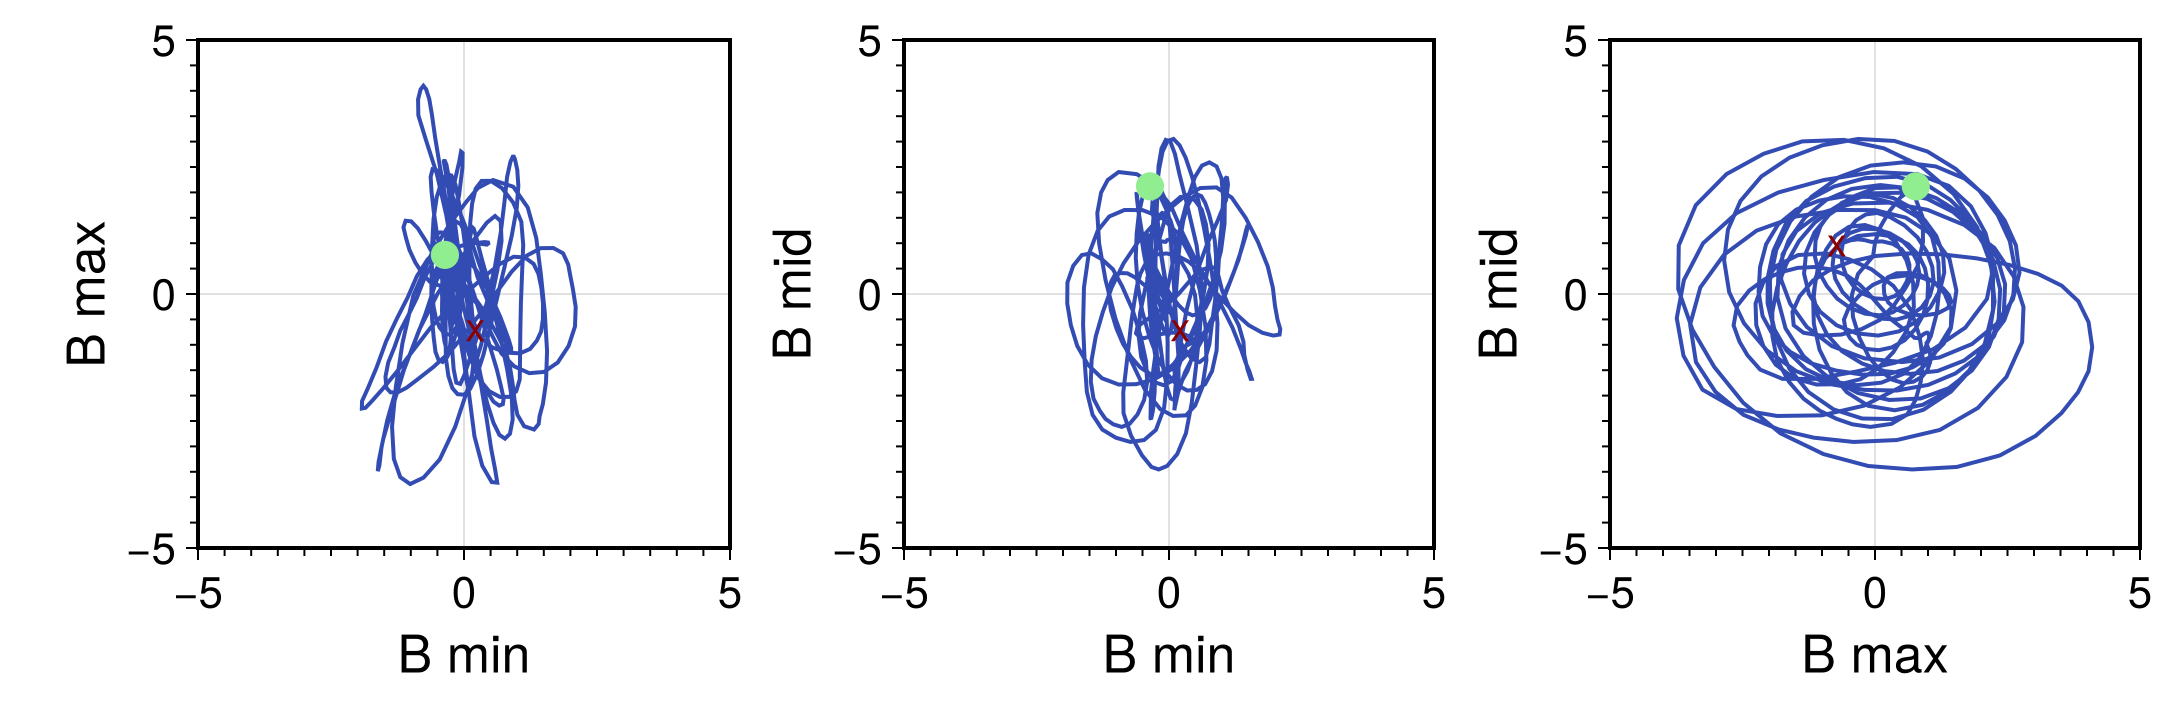

In [ ]:
Bwave = datawave1[:B].-mean(datawave1[:B], dims=1)

CairoMakie.activate!()
size_inches = (15, 5)
size_pt = 72 .* size_inches
fig = Figure(size = size_pt, fontsize = 24, figure_padding = (30, 10, 20, 20), rowgap = 20)
set_theme!(;
    Axis=(backgroundcolor = :white,
        bordercolor=:black, bordersize=15, spinewidth = 2, 
        xlabelsize=26, ylabelsize=26, xticklabelsize=22, yticklabelsize=22, 
        ticksize=8, minorticksize=4, 
        xminorticksvisible = true, yminorticksvisible = true,
        xminorticks = IntervalsBetween(10), yminorticks = IntervalsBetween(10))
)

ax_phase1 =  Axis(fig[1,1])
ax_phase2 =  Axis(fig[1,2])
ax_phase3 =  Axis(fig[1,3])
plot_MVA(ax_phase1,ax_phase2,ax_phase3,Bwave)
fig